       NEUROTRACE AI | INTELLIGENCE REPORT
Total observations:          970
Features analyzed:           6
Synthetic anomalies:         70
Detected anomalies:          70
Accuracy:                    0.984
Precision:                   0.886
Recall:                      0.886
F1-score:                    0.886
ROC-AUC:                     0.997
Average precision:           0.967
Cluster silhouette score:    0.317
PCA variance represented:    59.91%

Confusion Matrix
Rows = actual [normal, anomaly]
Columns = predicted [normal, anomaly]
[[892   8]
 [  8  62]]

TOP 10 HIGHEST-RISK OBSERVATIONS
Observation_ID  Signal_A  Signal_B  Signal_C  Signal_D  Signal_E  Signal_F  Relative_Risk_Score Detection_Result  Cluster
      OBS-0949     0.261    -4.382     3.668    -8.928     9.673    -4.410              100.000          Anomaly        1
      OBS-0935    -5.347    -2.974    -4.050     5.954    -7.160     0.070               98.063          Anomaly        0
      OBS-0946    -4.891    -3.579   

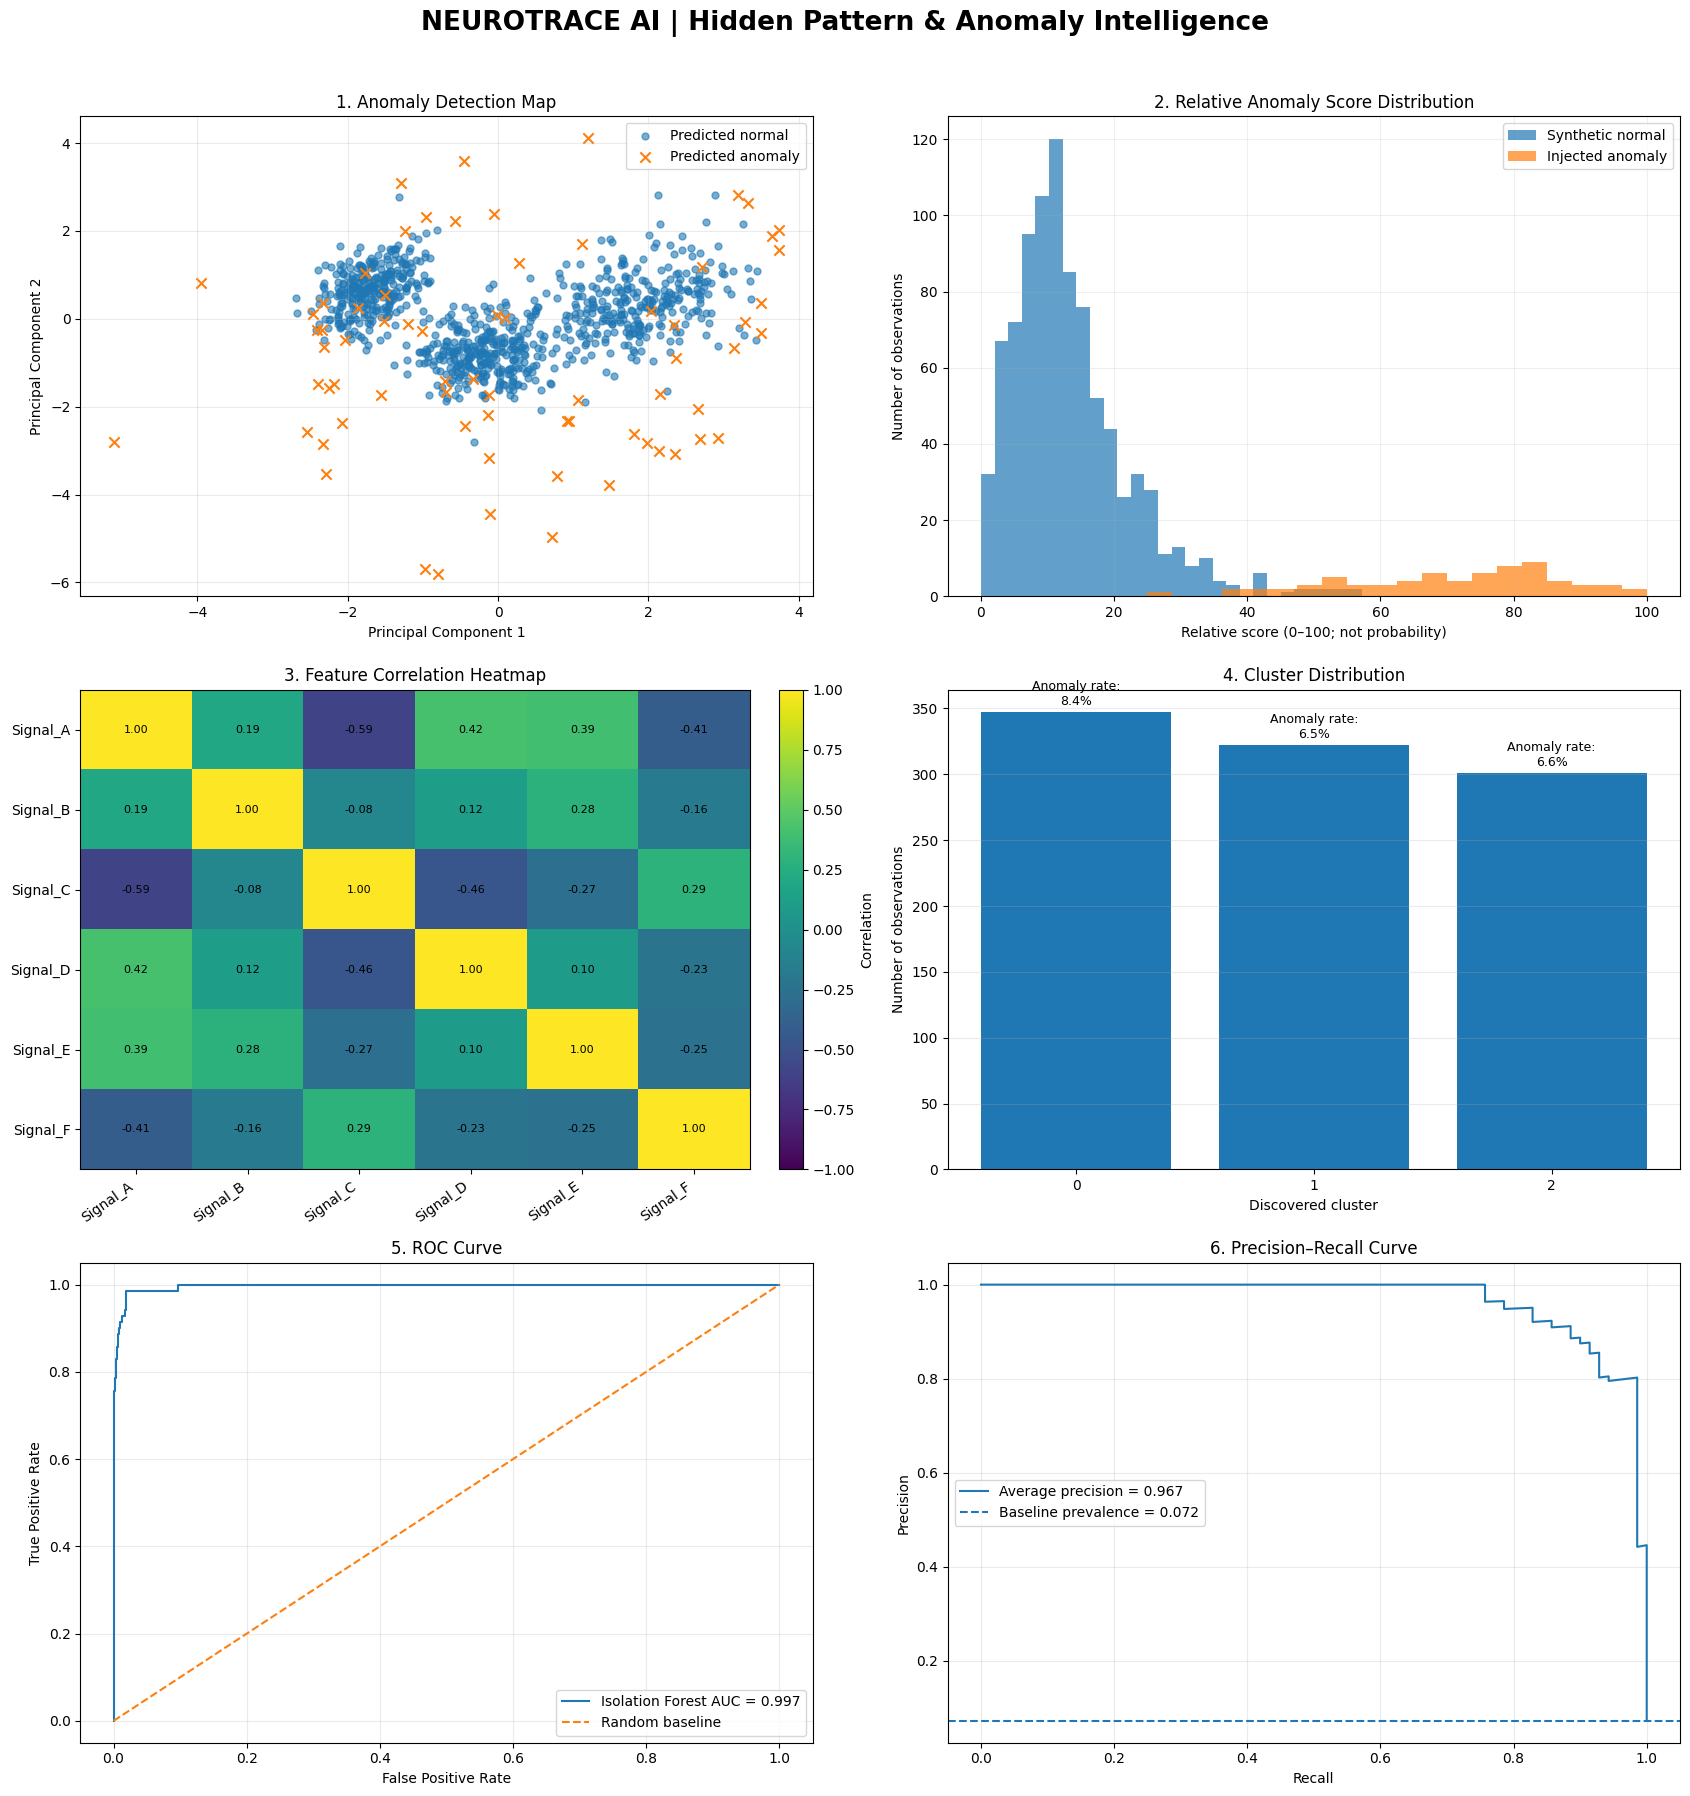


PROJECT FILES SAVED SUCCESSFULLY
Full results : neurotrace_ai_outputs/neurotrace_full_results.csv
Anomaly list : neurotrace_ai_outputs/neurotrace_detected_anomalies.csv
Metrics      : neurotrace_ai_outputs/neurotrace_metrics.csv
Dashboard    : neurotrace_ai_outputs/neurotrace_dashboard.png

NOTE: This experiment uses synthetic data.
Evaluation metrics do not guarantee real-world performance.


In [1]:
# ================================================================
# NEUROTRACE AI: HIDDEN PATTERN & ANOMALY DISCOVERY ENGINE
# Complete project + 6 visualizations + CSV exports in ONE CELL
# ================================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix,
    silhouette_score
)

# -------------------- CONFIGURATION --------------------
SEED = 42
N_NORMAL = 900
N_ANOMALIES = 70
N_FEATURES = 6
OUTPUT_DIR = "neurotrace_ai_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

FEATURES = [
    "Signal_A", "Signal_B", "Signal_C",
    "Signal_D", "Signal_E", "Signal_F"
]

# -------------------- 1. GENERATE DATA --------------------
centers = [
    [0, 0, 0, 0, 0, 0],
    [2, 1.8, -1, 1, 2.2, -0.5],
    [-2, 1, 2, -1.8, 0.4, 2]
]

X_normal, _ = make_blobs(
    n_samples=N_NORMAL,
    centers=centers,
    cluster_std=[0.75, 0.9, 0.8],
    random_state=SEED
)

# Introduce nonlinear patterns
X_normal[:, 3] += 0.35 * np.sin(X_normal[:, 0] * 1.5)
X_normal[:, 4] += 0.25 * X_normal[:, 1] ** 2
X_normal[:, 5] += 0.30 * X_normal[:, 0] * X_normal[:, 2]

# Inject deliberately unusual observations
X_anomaly = rng.uniform(-5.5, 5.5, size=(N_ANOMALIES, N_FEATURES))
X_anomaly[:, 3] += rng.choice([-4, 4], size=N_ANOMALIES)
X_anomaly[:, 4] += rng.choice([-3, 5], size=N_ANOMALIES)

X = np.vstack([X_normal, X_anomaly])

# Ground truth: 0 = normal, 1 = synthetic anomaly
y_true = np.concatenate([
    np.zeros(N_NORMAL, dtype=int),
    np.ones(N_ANOMALIES, dtype=int)
])

df = pd.DataFrame(X, columns=FEATURES)
df.insert(
    0, "Observation_ID",
    [f"OBS-{i:04d}" for i in range(1, len(df) + 1)]
)
df["Synthetic_Truth"] = y_true

# -------------------- 2. PREPROCESSING --------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURES])

# -------------------- 3. ANOMALY DETECTION --------------------
model = IsolationForest(
    n_estimators=300,
    contamination=N_ANOMALIES / len(df),
    random_state=SEED
)

model.fit(X_scaled)

# Larger score indicates a more unusual observation
scores = -model.score_samples(X_scaled)

# -1 = anomaly; 1 = normal
predictions = (model.predict(X_scaled) == -1).astype(int)

score_min = scores.min()
score_max = scores.max()

# Relative ranking score, NOT a probability
risk_scores = (
    100 * (scores - score_min) /
    (score_max - score_min + 1e-12)
)

df["Anomaly_Score"] = scores
df["Relative_Risk_Score"] = risk_scores
df["Predicted_Anomaly"] = predictions
df["Detection_Result"] = np.where(
    predictions == 1, "Anomaly", "Normal"
)

# -------------------- 4. CLUSTERING --------------------
kmeans = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=SEED
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

silhouette = silhouette_score(
    X_scaled, df["Cluster"]
)

# -------------------- 5. DIMENSIONALITY REDUCTION --------------------
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

df["PCA_1"] = X_pca[:, 0]
df["PCA_2"] = X_pca[:, 1]

pca_variance = pca.explained_variance_ratio_.sum() * 100

# -------------------- 6. EVALUATION --------------------
precision = precision_score(
    y_true, predictions, zero_division=0
)
recall = recall_score(
    y_true, predictions, zero_division=0
)
f1 = f1_score(
    y_true, predictions, zero_division=0
)
accuracy = np.mean(y_true == predictions)

roc_auc = roc_auc_score(y_true, scores)
avg_precision = average_precision_score(y_true, scores)

fpr, tpr, _ = roc_curve(y_true, scores)
pr_precision, pr_recall, _ = precision_recall_curve(
    y_true, scores
)

cm = confusion_matrix(
    y_true, predictions, labels=[0, 1]
)

# -------------------- 7. PRINT REPORT --------------------
print("=" * 65)
print("       NEUROTRACE AI | INTELLIGENCE REPORT")
print("=" * 65)

print(f"Total observations:          {len(df):,}")
print(f"Features analyzed:           {len(FEATURES)}")
print(f"Synthetic anomalies:         {N_ANOMALIES}")
print(f"Detected anomalies:          {predictions.sum()}")
print(f"Accuracy:                    {accuracy:.3f}")
print(f"Precision:                   {precision:.3f}")
print(f"Recall:                      {recall:.3f}")
print(f"F1-score:                    {f1:.3f}")
print(f"ROC-AUC:                     {roc_auc:.3f}")
print(f"Average precision:           {avg_precision:.3f}")
print(f"Cluster silhouette score:    {silhouette:.3f}")
print(f"PCA variance represented:    {pca_variance:.2f}%")

print("\nConfusion Matrix")
print("Rows = actual [normal, anomaly]")
print("Columns = predicted [normal, anomaly]")
print(cm)

print("\nTOP 10 HIGHEST-RISK OBSERVATIONS")

print(
    df.nlargest(10, "Relative_Risk_Score")[
        ["Observation_ID"] + FEATURES +
        ["Relative_Risk_Score", "Detection_Result", "Cluster"]
    ].round(3).to_string(index=False)
)

# -------------------- 8. SIX VISUALIZATIONS --------------------
fig, axes = plt.subplots(3, 2, figsize=(17, 18))

fig.suptitle(
    "NEUROTRACE AI | Hidden Pattern & Anomaly Intelligence",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

# VISUALIZATION 1: PCA ANOMALY MAP
ax = axes[0, 0]

normal_mask = predictions == 0
anomaly_mask = predictions == 1

ax.scatter(
    X_pca[normal_mask, 0],
    X_pca[normal_mask, 1],
    s=25,
    alpha=0.6,
    label="Predicted normal"
)

ax.scatter(
    X_pca[anomaly_mask, 0],
    X_pca[anomaly_mask, 1],
    s=55,
    marker="x",
    label="Predicted anomaly"
)

ax.set_title("1. Anomaly Detection Map")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend()
ax.grid(alpha=0.25)

# VISUALIZATION 2: RISK DISTRIBUTION
ax = axes[0, 1]

ax.hist(
    risk_scores[y_true == 0],
    bins=28,
    alpha=0.7,
    label="Synthetic normal"
)

ax.hist(
    risk_scores[y_true == 1],
    bins=20,
    alpha=0.7,
    label="Injected anomaly"
)

ax.set_title("2. Relative Anomaly Score Distribution")
ax.set_xlabel("Relative score (0–100; not probability)")
ax.set_ylabel("Number of observations")
ax.legend()
ax.grid(alpha=0.2)

# VISUALIZATION 3: CORRELATION HEATMAP
ax = axes[1, 0]

correlation = df[FEATURES].corr()

image = ax.imshow(
    correlation,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))

ax.set_xticklabels(FEATURES, rotation=35, ha="right")
ax.set_yticklabels(FEATURES)

ax.set_title("3. Feature Correlation Heatmap")

for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04,
    label="Correlation"
)

# VISUALIZATION 4: CLUSTER ANALYSIS
ax = axes[1, 1]

cluster_counts = df["Cluster"].value_counts().sort_index()
cluster_rates = df.groupby("Cluster")["Predicted_Anomaly"].mean()

bars = ax.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

ax.set_title("4. Cluster Distribution")
ax.set_xlabel("Discovered cluster")
ax.set_ylabel("Number of observations")
ax.grid(axis="y", alpha=0.25)

for bar, cluster_id in zip(bars, cluster_counts.index):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"Anomaly rate:\n{cluster_rates.loc[cluster_id]:.1%}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# VISUALIZATION 5: ROC CURVE
ax = axes[2, 0]

ax.plot(
    fpr, tpr,
    label=f"Isolation Forest AUC = {roc_auc:.3f}"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random baseline"
)

ax.set_title("5. ROC Curve")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.25)

# VISUALIZATION 6: PRECISION-RECALL CURVE
ax = axes[2, 1]

ax.plot(
    pr_recall,
    pr_precision,
    label=f"Average precision = {avg_precision:.3f}"
)

ax.axhline(
    y=y_true.mean(),
    linestyle="--",
    label=f"Baseline prevalence = {y_true.mean():.3f}"
)

ax.set_title("6. Precision–Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.98])

# Save the visualization dashboard
dashboard_file = os.path.join(
    OUTPUT_DIR, "neurotrace_dashboard.png"
)

plt.savefig(
    dashboard_file,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# -------------------- 9. EXPORT RESULTS --------------------
full_file = os.path.join(
    OUTPUT_DIR, "neurotrace_full_results.csv"
)

anomaly_file = os.path.join(
    OUTPUT_DIR, "neurotrace_detected_anomalies.csv"
)

metrics_file = os.path.join(
    OUTPUT_DIR, "neurotrace_metrics.csv"
)

df.to_csv(full_file, index=False)

df[df["Predicted_Anomaly"] == 1].sort_values(
    "Relative_Risk_Score",
    ascending=False
).to_csv(anomaly_file, index=False)

metrics = pd.DataFrame([{
    "observations": len(df),
    "features": len(FEATURES),
    "synthetic_anomalies": N_ANOMALIES,
    "detected_anomalies": int(predictions.sum()),
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "average_precision": avg_precision,
    "silhouette_score": silhouette,
    "pca_variance_percent": pca_variance
}])

metrics.to_csv(metrics_file, index=False)

print("\n" + "=" * 65)
print("PROJECT FILES SAVED SUCCESSFULLY")
print("=" * 65)
print("Full results :", full_file)
print("Anomaly list :", anomaly_file)
print("Metrics      :", metrics_file)
print("Dashboard    :", dashboard_file)
print("\nNOTE: This experiment uses synthetic data.")
print("Evaluation metrics do not guarantee real-world performance.")